# UTS Graf Sains Data: Rekomendasi RetailRocket dengan Neo4j

Alur: filter 2 periode (P1 = training, P2 = testing) -> impor P1 ke Neo4j -> komposisi subgraph -> VSM User & Item -> pilih proyeksi -> similarity -> KNN -> Hit@5 & NDCG@5.

In [ ]:
import os
import numpy as np, pandas as pd, networkx as nx, matplotlib.pyplot as plt
from scipy import sparse
from sklearn.preprocessing import normalize
from neo4j import GraphDatabase, RoutingControl
from tqdm import tqdm
from IPython.display import display, Markdown

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", os.environ.get("NEO4J_PASSWORD", "password"))   # isi password lewat env var NEO4J_PASSWORD, jangan hardcode
DB = "neo4j"
DATA_DIR = "data"

# #22
P1 = ("2015-06-16", "2015-06-30")
P2 = ("2015-07-01", "2015-07-15")

SEED = 42
TOP_N = 10000
BATCH = 50000
EVENT_W = {"view": 1, "addtocart": 3, "transaction": 5}
REL = {"view": "VIEWED", "addtocart": "ADDED_TO_CART", "transaction": "BOUGHT"}
RELS = "VIEWED|ADDED_TO_CART|BOUGHT"

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

def q(cypher:str, write=False, **params):
    kw = {} if write else {"routing_": RoutingControl.READ}
    records, _, _ = driver.execute_query(cypher, parameters_=params, database_=DB, **kw)
    return pd.DataFrame([r.data() for r in records])

def show(text):
    display(Markdown(text))

## B. 2.1 Wrangling dan EDA
### 2.1 No. 1: Penentuan dua periode waktu
**Soal:** tentukan 2 periode sebagai filter data interaksi (kombinasi harus unik per mahasiswa).

In [36]:
df = pd.read_csv(os.path.join(DATA_DIR, "events.csv"))
df["dt"] = pd.to_datetime(df["timestamp"], unit="ms")   # timestamp RetailRocket = epoch milidetik

def cut(d, start, end):
    # batas akhir inklusif sampai pukul 23:59:59 pada tanggal akhir
    return d[(d.dt >= pd.Timestamp(start)) & (d.dt < pd.Timestamp(end) + pd.Timedelta(days=1))]

p1, p2 = cut(df, *P1), cut(df, *P2)

show(
    f"**Hasil filter:** total data {len(df):,} baris.  \n"
    f"P1 (training) {P1[0]} s/d {P1[1]} = **{len(p1):,}** baris.  \n"
    f"P2 (testing) {P2[0]} s/d {P2[1]} = **{len(p2):,}** baris."
)

display(p1['event'].value_counts().rename("jumlah P1").to_frame().join(p2["event"].value_counts().rename("jumlah P2")))

**Hasil filter:** total data 2,756,101 baris.  
P1 (training) 2015-06-16 s/d 2015-06-30 = **309,830** baris.  
P2 (testing) 2015-07-01 s/d 2015-07-15 = **333,778** baris.

,jumlah P1,jumlah P2
event,,
view,299133,322990
addtocart,7985,8099
transaction,2712,2689


**Jawaban:** periode yang saya pilih adalah kombinasi **#22**: P1 (training) 16-30 Juni 2015 dan P2 (testing) 01-15 Juli 2015. Kedua periode berurutan sehingga ada user yang muncul di keduanya, yang diperlukan untuk evaluasi di 2.2.

### 2.1 No. 2: Simpan hasil filter ke .csv
**Soal:** terapkan filter pada timestamp saat persiapan data, lalu simpan ke file .csv.

In [37]:
CSV_P1, CSV_P2 = "events_p1.csv", "events_p2.csv"
p1.drop(columns="dt").to_csv(CSV_P1, index=False)
p2.drop(columns="dt").to_csv(CSV_P2, index=False)
show(f"Tersimpan: `{CSV_P1}` ({len(p1):,} baris) dan `{CSV_P2}` ({len(p2):,} baris).")

Tersimpan: `events_p1.csv` (309,830 baris) dan `events_p2.csv` (333,778 baris).

**Jawaban:** filter dilakukan pada kolom `timestamp` (epoch milidetik, dikonversi ke datetime), lalu hasilnya disimpan sebagai `events_p1.csv` (training, digunakan membangun graf) dan `events_p2.csv` (testing, digunakan sebagai ground truth evaluasi).

### Impor P1 ke Neo4j (Tugas 1.3)
Hanya P1 yang masuk graf. Jalankan sekali. Bila perlu mengulang, jalankan dulu reset di bawah (hati-hati pada shared database).

In [38]:
# RESET (hapus tanda # bila ingin mengosongkan database, termasuk sisa tutorial 1.2):
# q("MATCH (n) DETACH DELETE n", write=True)

CY_VIEW = '''
UNWIND $rows AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
'''
CY_CART = '''
UNWIND $rows AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
'''
CY_BUY = '''
UNWIND $rows AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
'''
QUERY = {"view": CY_VIEW, "addtocart": CY_CART, "transaction": CY_BUY}

driver.execute_query("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE", database_=DB)
driver.execute_query("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE", database_=DB)

for chunk in tqdm(pd.read_csv(CSV_P1, chunksize=BATCH)):
    for event, cypher in QUERY.items():
        part = chunk[chunk["event"] == event].copy()
        if part.empty:
            continue
        if event == "transaction":
            part["transactionid"] = part["transactionid"].astype(int)   # NaN di CSV membuatnya float
        rows = part[["visitorid", "itemid", "timestamp", "transactionid"]].to_dict("records")
        driver.execute_query(cypher, rows=rows, database_=DB)

print("Impor selesai.")

7it [00:34,  4.88s/it]

Impor selesai.


### 2.1 No. 3: Komposisi subgraph
**Soal:** query komposisi subgraph, uraikan jenis simpul dan jumlahnya dengan Python API, jelaskan Cypher yang dipakai.

In [39]:
CY_NODES = 'MATCH (n) UNWIND labels(n) AS label RETURN label, count(*) AS jumlah ORDER BY jumlah DESC'
CY_RELS = 'MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah ORDER BY jumlah DESC'

nodes, rels = q(CY_NODES), q(CY_RELS)
display(nodes); display(rels)
ringkas_n = ", ".join(f"{r.label}: {r.jumlah:,}" for r in nodes.itertuples())
ringkas_r = ", ".join(f"{r.relasi}: {r.jumlah:,}" for r in rels.itertuples())
show(
    f"**Komposisi graf:**  \n"
    f"- **Simpul:** {int(nodes['jumlah'].sum()):,} ({ringkas_n})  \n"
    f"- **Relasi:** {int(rels['jumlah'].sum()):,} ({ringkas_r})  \n"
    f"- **Pengecekan:** jumlah baris P1 = {len(p1):,}."
)

,label,jumlah
0,Visitor,161249
1,Item,81034


,relasi,jumlah
0,VIEWED,299133
1,ADDED_TO_CART,7985
2,BOUGHT,2712


**Komposisi graf:**  
- **Simpul:** 242,283 (Visitor: 161,249, Item: 81,034)  
- **Relasi:** 309,830 (VIEWED: 299,133, ADDED_TO_CART: 7,985, BOUGHT: 2,712)  
- **Pengecekan:** jumlah baris P1 = 309,830.

**Jawaban (penjelasan Cypher):**
- `MATCH (n)` mengambil semua simpul di graf.
- `UNWIND labels(n) AS label` memecah daftar label tiap simpul menjadi satu baris per label.
- `RETURN label, count(*) AS jumlah` mengelompokkan per label dan menghitung jumlahnya. `ORDER BY jumlah DESC` mengurutkan dari yang terbanyak.
- `MATCH ()-[r]->()` mengambil semua relasi berarah, lalu `type(r)` memberi jenis relasinya (VIEWED, ADDED_TO_CART, BOUGHT).
- Jenis simpul: **Visitor** (user) dan **Item**. Python API dipakai lewat `driver.execute_query(...)`, hasilnya diubah menjadi DataFrame oleh fungsi `q()`.
- Jumlah total relasi harus sama dengan jumlah baris P1, karena tiap baris event menjadi satu relasi.

### 2.1 No. 4: VSM terhadap simpul User
**Soal:** lakukan VSM pada simpul User, uraikan karakteristiknya (dimensi, shape, plot networkx, dst.).
Tiap **baris** matriks adalah vektor satu User, tiap **kolom** adalah satu Item, nilainya jumlah bobot interaksi (view=1, addtocart=3, transaction=5).

**VSM User:** shape = **161,249 x 81,034** (user x item), nonzero = 239,550, density = 1.83e-05. Rata-rata 1.49 item per user (median 1, maks 874); 80.9% user hanya menyentuh 1 item.

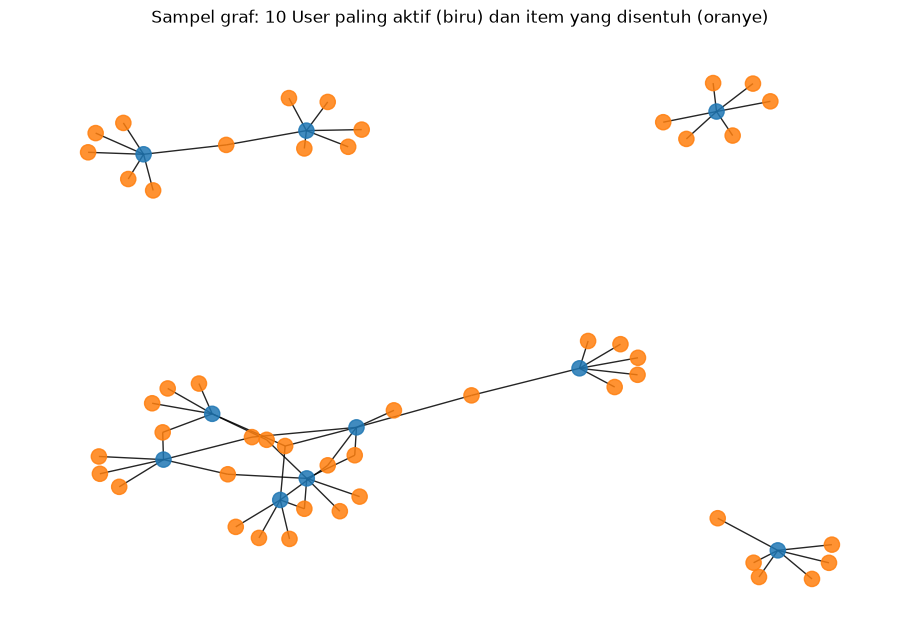

In [40]:
d = pd.read_csv(CSV_P1)
d["w"] = d["event"].map(EVENT_W)
d["ui"], user_ids = pd.factorize(d["visitorid"])
d["ii"], item_ids = pd.factorize(d["itemid"])
M = sparse.coo_matrix((d["w"].values, (d["ui"].values, d["ii"].values)),
                      shape=(len(user_ids), len(item_ids))).tocsr()   # entri ganda (user, item) otomatis dijumlah

def karakter(A):
    per_vektor = np.asarray((A > 0).sum(axis=1)).ravel()
    return {"shape": A.shape, "nnz": A.nnz, "density": A.nnz / (A.shape[0] * A.shape[1]),
            "rata": per_vektor.mean(), "median": float(np.median(per_vektor)),
            "maks": int(per_vektor.max()), "satu": float((per_vektor == 1).mean())}

ku = karakter(M)
show(f'''**VSM User:** shape = **{ku["shape"][0]:,} x {ku["shape"][1]:,}** (user x item), nonzero = {ku["nnz"]:,}, '''
     f'''density = {ku["density"]:.2e}. Rata-rata {ku["rata"]:.2f} item per user (median {ku["median"]:.0f}, maks {ku["maks"]:,}); '''
     f'''{ku["satu"]:.1%} user hanya menyentuh 1 item.''')

# Plot networkx: 10 user paling aktif dan item yang mereka sentuh (sampel)
deg_u = np.asarray((M > 0).sum(axis=1)).ravel()
top_users = np.argsort(-deg_u)[:10]
G = nx.Graph()
for u in top_users:
    for c in M[u].indices[:6]:
        G.add_edge(f"U{user_ids[u]}", f"I{item_ids[c]}")
plt.figure(figsize=(9, 6))
nx.draw(G, nx.spring_layout(G, seed=SEED), node_size=120, alpha=.85, with_labels=False,
        node_color=["tab:blue" if n.startswith("U") else "tab:orange" for n in G.nodes])
plt.title("Sampel graf: 10 User paling aktif (biru) dan item yang disentuh (oranye)"); plt.show()

**Jawaban:** VSM User berukuran 161.249 x 81.034 dengan density 1,83e-05, sehingga sangat sparse. Rata-rata user hanya menyentuh 1,49 item (median 1) dan 80,9% user hanya menyentuh satu item, meski ada user ekstrem hingga 874 item. Plot networkx (sampel 10 user paling aktif, dipotong 6 item per user) menunjukkan struktur bipartit: sebagian user terhubung lewat item yang sama, sedangkan sisanya membentuk klaster terpisah. Irisan item antar-user yang kecil membuat kemiripan user-user sulit dihitung andal.

### 2.1 No. 5: VSM terhadap simpul Item
**Soal:** lakukan VSM pada simpul Item, uraikan karakteristiknya (dimensi, shape, plot networkx, dst.).
Tiap **baris** adalah vektor satu Item, tiap **kolom** adalah satu User (matriks transpos dari No. 4).

**VSM Item:** shape = **81,034 x 161,249** (item x user), nonzero = 239,550, density = 1.83e-05. Rata-rata 2.96 user per item (median 1, maks 257); 54.6% item hanya disentuh 1 user.

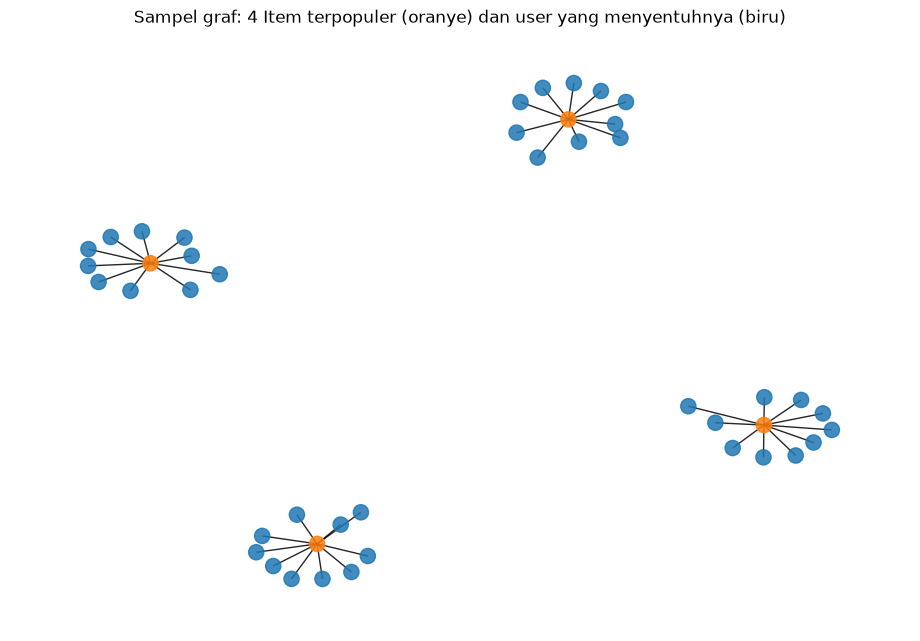

In [41]:
Mt = M.T.tocsr()
ki = karakter(Mt)
show(f'''**VSM Item:** shape = **{ki["shape"][0]:,} x {ki["shape"][1]:,}** (item x user), nonzero = {ki["nnz"]:,}, '''
     f'''density = {ki["density"]:.2e}. Rata-rata {ki["rata"]:.2f} user per item (median {ki["median"]:.0f}, maks {ki["maks"]:,}); '''
     f'''{ki["satu"]:.1%} item hanya disentuh 1 user.''')

deg_i = np.asarray((Mt > 0).sum(axis=1)).ravel()
top_items = np.argsort(-deg_i)[:4]
Gi = nx.Graph()
for i in top_items:
    for u in Mt[i].indices[:10]:
        Gi.add_edge(f"I{item_ids[i]}", f"U{user_ids[u]}")
plt.figure(figsize=(9, 6))
nx.draw(Gi, nx.spring_layout(Gi, seed=SEED), node_size=120, alpha=.85, with_labels=False,
        node_color=["tab:orange" if n.startswith("I") else "tab:blue" for n in Gi.nodes])
plt.title("Sampel graf: 4 Item terpopuler (oranye) dan user yang menyentuhnya (biru)"); plt.show()

**Jawaban:** VSM Item berukuran 81.034 x 161.249 (transpos dari VSM User) dengan density 1,83e-05. Rata-rata item disentuh 2,96 user (median 1, maks 257), dan 54,6% item hanya disentuh satu user. Plot (4 item terpopuler, 10 user per item) menunjukkan item populer sebagai hub yang dikelilingi banyak user, tanpa user bersama antar hub pada sampel ini. Vektor item lebih padat daripada vektor user, tetapi tetap sparse.

### 2.1 No. 6: Proyeksi mana yang lebih baik (efektif/efisien)?
**Soal:** berdasarkan No. 4 dan 5, uraikan proyeksi yang lebih baik.

In [42]:
B = (M > 0).astype(np.float32).tocsr()
n_u, n_i = B.shape
rng = np.random.default_rng(SEED)
su = rng.choice(n_u, size=min(3000, n_u), replace=False)
UU = B[su] @ B[su].T                                # proyeksi user-user (sampel 3000 user)
pop = np.asarray(B.sum(axis=0)).ravel()
top = np.argsort(-pop)[:TOP_N]                      # kolom item terpopuler
II = B[:, top].T @ B[:, top]                        # proyeksi item-item (TOP_N item)

show(f'''**Dimensi penuh:** user-user = {n_u:,} x {n_u:,} ({n_u**2:,} sel); item-item = {n_i:,} x {n_i:,} ({n_i**2:,} sel). '''
     f'''Rasio ukuran user-user : item-item = **{n_u**2 / n_i**2:,.1f} : 1**.''')
show(f'''**Sampel terhitung:** user-user ({len(su):,} user) nnz = {UU.nnz:,}, density = {UU.nnz / UU.shape[0]**2:.4f}; '''
     f'''item-item ({len(top):,} item) nnz = {II.nnz:,}, density = {II.nnz / II.shape[0]**2:.4f}.''')

**Dimensi penuh:** user-user = 161,249 x 161,249 (26,001,240,001 sel); item-item = 81,034 x 81,034 (6,566,509,156 sel). Rasio ukuran user-user : item-item = **4.0 : 1**.

**Sampel terhitung:** user-user (3,000 user) nnz = 3,892, density = 0.0004; item-item (10,000 item) nnz = 1,375,384, density = 0.0138.

**Jawaban:** Proyeksi item-item lebih baik. Pertama, ukurannya lebih kecil: 81.034 x 81.034 (sekitar 6,57 miliar sel) dibanding 161.249 x 161.249 (sekitar 26,0 miliar sel), rasio 4:1. Kedua, pada sampel, proyeksi user-user (3.000 user acak) hanya memiliki 892 pasangan user berbeda yang berbagi item karena 80,9% user hanya menyentuh satu item, sedangkan proyeksi item-item (10.000 item terpopuler) memiliki sekitar 1,37 juta pasangan dengan density 1,38%. Catatan: sampel item berasal dari item terpopuler sehingga perbandingan density bersifat indikatif. Ketiga, katalog item lebih stabil daripada populasi user. Karena itu similarity dan KNN dihitung pada proyeksi item-item.

### 2.1 No. 7: Perhitungan similarity pada proyeksi terpilih
**Soal:** hitung similarity pada graf terproyeksi dengan Python.
Metode: **cosine similarity** antar vektor item pada matriks berbobot `M` (TOP_N item terpopuler).

In [43]:
Mn = normalize(M[:, top].T.tocsr())            # TOP_N x user, tiap baris dinormalisasi L2
S = (Mn @ Mn.T).tocsr()                        # cosine = dot product vektor ternormalisasi
S = (S - sparse.diags(S.diagonal())).tocsr()   # buang self-similarity
S = S.multiply((II >= 3).astype(np.float32)).tocsr()   # II = jumlah user bersama; buang pasangan dengan < 3 user bersama
S.eliminate_zeros()

ref_col = 0                                    # item acuan = item terpopuler
ref_item = int(item_ids[top[ref_col]])
row = S.getrow(ref_col).toarray().ravel()
nn = np.argsort(-row)[:5]
top5 = [{"a": ref_item, "b": int(item_ids[top[j]]), "score": float(row[j])} for j in nn]
show(f"Matriks similarity {S.shape[0]:,} x {S.shape[1]:,}, nonzero = {S.nnz:,}. Item acuan: **{ref_item}**.")
display(pd.DataFrame(top5).rename(columns={"a": "acuan", "b": "item_mirip", "score": "cosine_berbobot"}))

Matriks similarity 10,000 x 10,000, nonzero = 20,240. Item acuan: **309778**.

,acuan,item_mirip,cosine_berbobot
0,309778,257040,0.143827
1,309778,347414,0.142836
2,309778,441966,0.141773
3,309778,369933,0.110922
4,309778,369158,0.101490


In [44]:
print("Item yang punya tetangga:", int((S.getnnz(axis=1) > 0).sum()), "dari", S.shape[0])

Item yang punya tetangga: 3250 dari 10000


**Jawaban:** Similarity dihitung dengan cosine pada vektor item berbobot (10.000 item terpopuler). Pasangan item dengan kurang dari 3 user bersama dibuang agar similarity tidak bergantung pada satu atau dua user saja, sehingga tersisa 20.240 entri tidak nol pada matriks 10.000 x 10.000. Untuk item acuan 309778, lima item paling mirip memiliki cosine 0,101-0,144, dengan item teratas 257040 (0,144). Item 257040 dan 347414 juga muncul pada query Cypher 7a, yang menunjukkan hasil Python konsisten dengan graf. Setelah filter minimal 3 user bersama, 3.250 dari 10.000 item (32,5%) memiliki setidaknya satu tetangga; item tanpa tetangga tidak menghasilkan rekomendasi.

#### 2.1 No. 7(a): Cypher untuk 5 record dengan similarity tertinggi
**Soal:** tuliskan Cypher untuk 5 record similarity tertinggi (acuan ditentukan sendiri).

Query ini menghitung **cosine biner** (ada/tidaknya interaksi) langsung dari graf, tanpa menunggu nilai ditulis. Ini cross-check independen, jadi angkanya boleh sedikit beda dari cosine berbobot di Python.

In [45]:
CY_SIM = '''
MATCH (a:Item {itemId: $id})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)
WHERE a <> b
WITH a, b, count(DISTINCT v) AS common
MATCH (a)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(va:Visitor)
WITH a, b, common, count(DISTINCT va) AS na
MATCH (b)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(vb:Visitor)
WITH b, common, na, count(DISTINCT vb) AS nb
RETURN b.itemId AS item_mirip, common AS user_bersama, common / sqrt(na * nb) AS cosine_biner
ORDER BY cosine_biner DESC LIMIT 5
'''
print(CY_SIM)
display(q(CY_SIM, id=ref_item))


MATCH (a:Item {itemId: $id})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)
WHERE a <> b
WITH a, b, count(DISTINCT v) AS common
MATCH (a)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(va:Visitor)
WITH a, b, common, count(DISTINCT va) AS na
MATCH (b)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(vb:Visitor)
WITH b, common, na, count(DISTINCT vb) AS nb
RETURN b.itemId AS item_mirip, common AS user_bersama, common / sqrt(na * nb) AS cosine_biner
ORDER BY cosine_biner DESC LIMIT 5



,item_mirip,user_bersama,cosine_biner
0,257040,44,0.218352
1,360487,21,0.166363
2,248327,9,0.150042
3,347414,14,0.141667
4,5470,12,0.103804


In [46]:
a = B[:, top[ref_col]].toarray().ravel()
for j in nn:
    print(int(item_ids[top[j]]), "user bersama:", int(a @ B[:, top[j]].toarray().ravel()))

257040 user bersama: 44
347414 user bersama: 14
441966 user bersama: 4
369933 user bersama: 3
369158 user bersama: 4


**Jawaban:** Query menghitung cosine biner langsung dari graf: common adalah jumlah user yang menyentuh kedua item, na dan nb jumlah user tiap item, cosine = common / sqrt(na x nb). Untuk item acuan 309778, item paling mirip adalah 257040 (44 user bersama, cosine 0,218), diikuti 360487 (21 user, 0,166), 248327 (9 user, 0,150), 347414 (14 user, 0,142), dan 5470 (12 user, 0,104).

### 2.1 No. 8 (kondisi SEBELUM similarity ditulis)
**Soal:** tuliskan Cypher dan tunjukkan graf untuk kondisi sebelum dan sesudah perhitungan similarity.
**Jalankan sel ini sebelum sel 7(b).**


MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item {itemId: $id})
RETURN v.visitorId AS visitor, type(r) AS relasi, i.itemId AS item LIMIT 10



,relasi,jumlah
0,ADDED_TO_CART,7985
1,BOUGHT,2712
2,VIEWED,299133


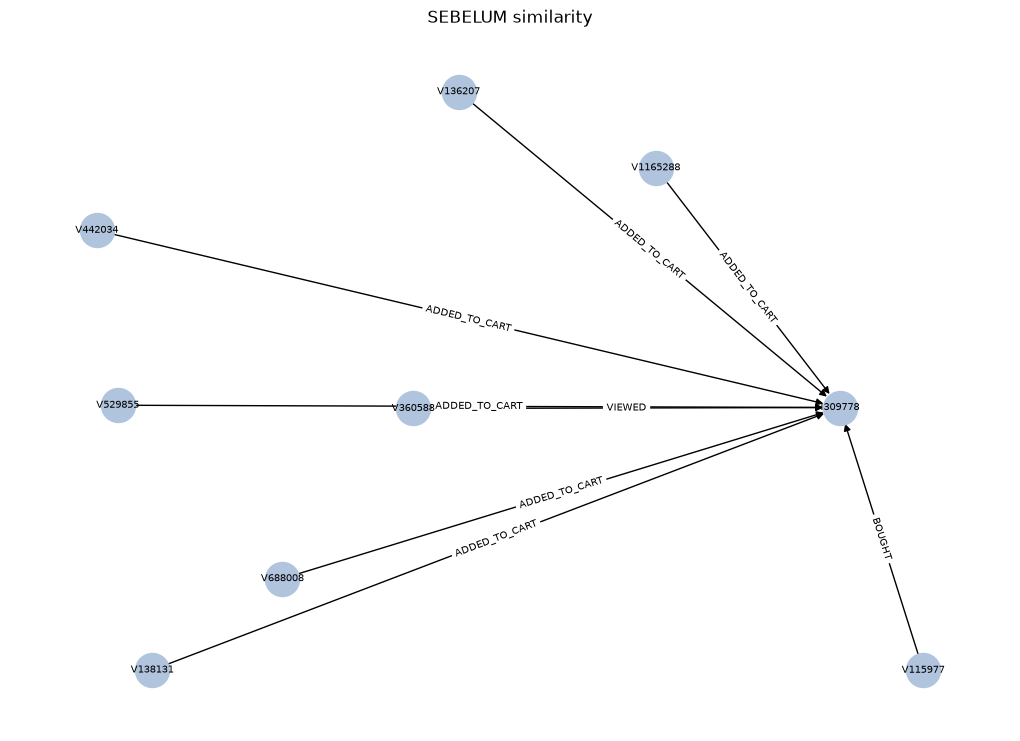

In [47]:
CY_BEFORE = '''
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item {itemId: $id})
RETURN v.visitorId AS visitor, type(r) AS relasi, i.itemId AS item LIMIT 10
'''
CY_AFTER_EXTRA = '''
MATCH (i:Item {itemId: $id})-[s:SIMILAR_TO]->(j:Item)
RETURN i.itemId AS item, j.itemId AS item_mirip, s.score AS similarity
'''

def gambar(df_v, df_s, judul):
    g = nx.DiGraph()
    for r in df_v.itertuples():
        g.add_edge(f"V{r.visitor}", f"I{r.item}", label=r.relasi)
    for r in df_s.itertuples():
        g.add_edge(f"I{r.item}", f"I{r.item_mirip}", label=f"{r.similarity:.3f}")
    pos = nx.spring_layout(g, seed=SEED)
    plt.figure(figsize=(10, 7))
    nx.draw(g, pos, with_labels=True, node_size=600, font_size=7, node_color="lightsteelblue")
    nx.draw_networkx_edge_labels(g, pos, edge_labels=nx.get_edge_attributes(g, "label"), font_size=7)
    plt.title(judul); plt.show()

print(CY_BEFORE)
before_rels = q("MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah ORDER BY relasi")
display(before_rels)
gambar(q(CY_BEFORE, id=ref_item), pd.DataFrame(columns=["item", "item_mirip", "similarity"]), "SEBELUM similarity")

#### 2.1 No. 7(b): Tuliskan nilai similarity ke graf
**Soal:** tulis kembali nilai similarity pada graf yang ada dan perlihatkan hasil query-nya.
Nilai cosine berbobot dari Python ditulis sebagai relasi `SIMILAR_TO` dengan properti `score`.

In [48]:
CY_WRITE = '''
UNWIND $rows AS r
MATCH (a:Item {itemId: r.a}), (b:Item {itemId: r.b})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = r.score
'''
print(CY_WRITE)
q(CY_WRITE, write=True, rows=top5)

CY_READBACK = '''
MATCH (a:Item {itemId: $id})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS acuan, b.itemId AS item_mirip, s.score AS similarity
ORDER BY s.score DESC LIMIT 5
'''
print(CY_READBACK)
display(q(CY_READBACK, id=ref_item))


UNWIND $rows AS r
MATCH (a:Item {itemId: r.a}), (b:Item {itemId: r.b})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = r.score


MATCH (a:Item {itemId: $id})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS acuan, b.itemId AS item_mirip, s.score AS similarity
ORDER BY s.score DESC LIMIT 5



,acuan,item_mirip,similarity
0,309778,257040,0.143827
1,309778,347414,0.142836
2,309778,441966,0.141773
3,309778,369933,0.110922
4,309778,369158,0.101490


**Jawaban:** `MERGE` membuat relasi `SIMILAR_TO` hanya sekali (idempoten bila sel diulang) dan `SET` mengisi properti `score`. Query pembacaan di atas menunjukkan 5 relasi baru beserta nilainya.

### 2.1 No. 8 (kondisi SESUDAH similarity ditulis)


MATCH (i:Item {itemId: $id})-[s:SIMILAR_TO]->(j:Item)
RETURN i.itemId AS item, j.itemId AS item_mirip, s.score AS similarity



,relasi,jumlah
0,ADDED_TO_CART,7985
1,BOUGHT,2712
2,SIMILAR_TO,5
3,VIEWED,299133


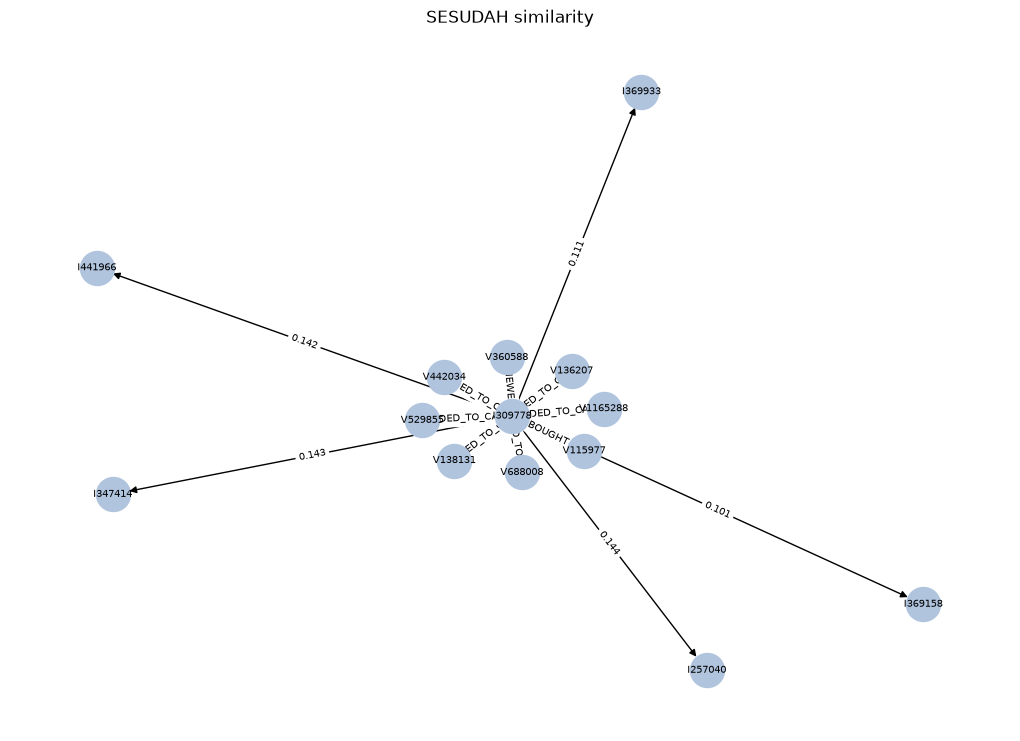

In [49]:
print(CY_AFTER_EXTRA)
after_rels = q("MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah ORDER BY relasi")
display(after_rels)
gambar(q(CY_BEFORE, id=ref_item), q(CY_AFTER_EXTRA, id=ref_item), "SESUDAH similarity")

**Jawaban:** sebelum similarity, graf hanya berisi relasi VIEWED, ADDED_TO_CART, dan BOUGHT. Sesudahnya muncul jenis relasi baru `SIMILAR_TO` (5 relasi) antar-item, dengan nilai similarity sebagai label. Ini terlihat pada tabel jumlah relasi dan pada gambar graf.

## C. 2.2 Analytics
### 2.2 No. 1(a): Pilih user acak (reproducible) dan skrip KNN
**Soal:** pilih user secara acak (proses acak harus bisa direproduksi), lalu tulis skrip Python rekomendasi KNN.

Metode: **item-based KNN**. Untuk tiap item yang pernah disentuh user, ambil `k` tetangga terdekat (cosine), jumlahkan bobot x similarity, buang item yang sudah pernah dilihat, lalu urutkan.
Definisi relevan: item yang disentuh user di P2 (semua jenis event) dan termasuk TOP_N item kandidat.

In [ ]:
col_of = {int(item_ids[t]): c for c, t in enumerate(top)}      # itemId -> kolom pada S
u_of = {int(u): i for i, u in enumerate(user_ids)}             # visitorId -> baris pada M
seen_cnt = np.asarray((M[:, top] > 0).sum(axis=1)).ravel()

p2d = pd.read_csv(CSV_P2)
p2d = p2d[p2d["itemid"].isin(list(col_of))]
relevant = p2d.groupby("visitorid")["itemid"].apply(set).to_dict()

eligible = sorted(u for u in relevant if u in u_of and seen_cnt[u_of[u]] > 0)
show(f"User yang memenuhi syarat (punya riwayat di P1 dan interaksi di P2): **{len(eligible):,}**.")

def recommend(u_idx, k=5, n=5):
    row = M[u_idx][:, top]
    scores = np.zeros(len(top))
    for c, w in zip(row.indices, row.data):                    # tiap item yang pernah disentuh user
        s = S.getrow(c)
        if s.nnz == 0:
            continue
        sel = np.argsort(-s.data)[:k]                          # k tetangga terdekat item tersebut
        scores[s.indices[sel]] += w * s.data[sel]
    scores[row.indices] = -np.inf                              # jangan rekomendasikan yang sudah pernah disentuh
    best = np.argsort(-scores)[:n]
    return [int(item_ids[top[b]]) for b in best if scores[b] > 0]

In [51]:
rng = np.random.default_rng(SEED)      # seed tetap -> user yang sama terpilih setiap dijalankan
punya_rek = [u for u in eligible if len(recommend(u_of[u], k=5, n=5)) >= 3]
target = int(rng.choice(punya_rek))
show(f"User eligible: **{len(eligible):,}**; yang punya >= 3 rekomendasi: **{len(punya_rek):,}** "
     f"({len(punya_rek)/len(eligible):.1%}). User terpilih (seed={SEED}): **{target}**.")

User eligible: **3,160**; yang punya >= 3 rekomendasi: **1,283** (40.6%). User terpilih (seed=42): **142957**.

**Jawaban:** pemilihan acak memakai `np.random.default_rng(42)` sehingga user yang sama terpilih tiap kali dijalankan (reproducible). User dipilih acak dari user eligible yang memiliki minimal 3 rekomendasi, agar 3 item iklan di no. 1b dapat ditampilkan (user tanpa rekomendasi menghasilkan daftar kosong). KNN dilakukan pada item: tiap item yang pernah disentuh user menyumbang skor ke 5 tetangga terdekatnya sebesar (bobot interaksi x cosine), item yang sudah pernah disentuh dikeluarkan, lalu diurutkan menurun.

### 2.2 No. 1(b): 3 item yang diiklankan untuk k = 5

In [52]:
recs5 = recommend(u_of[target], k=5, n=5)
show(f"**3 item yang diiklankan untuk user {target} (k = 5):** {recs5[:3]}")
show(f"Top-5 (dipakai untuk evaluasi): {recs5}. Item relevan di P2: {sorted(relevant[target])[:20]}"
     f"{' ...' if len(relevant[target]) > 20 else ''}")

**3 item yang diiklankan untuk user 142957 (k = 5):** [400442, 192653, 7804]

Top-5 (dipakai untuk evaluasi): [400442, 192653, 7804, 25762, 206241]. Item relevan di P2: [445115, 454422]

**Jawaban:** 3 item teratas dari hasil KNN (k = 5) adalah item iklan untuk user terpilih. Evaluasi di 2.2 No. 2 memakai top-5 dari KNN yang sama, karena Hit@5 dan NDCG@5 butuh lima rekomendasi.

### 2.2 No. 2: Evaluasi rekomendasi
**Soal:** berdasarkan rekomendasi No. 1b, hitung (a) Hit@5 dan (b) NDCG@5.

In [ ]:
def hit_at_k(recs, rel, k=5):
    return int(any(r in rel for r in recs[:k]))

def ndcg_at_k(recs, rel, k=5):
    dcg = sum(1 / np.log2(i + 2) for i, r in enumerate(recs[:k]) if r in rel)
    idcg = sum(1 / np.log2(i + 2) for i in range(min(k, len(rel))))
    return dcg / idcg if idcg else 0.0

rel = relevant[target]
h, n5 = hit_at_k(recs5, rel), ndcg_at_k(recs5, rel)
show(f"**User {target}:** Hit@5 = **{h}**, NDCG@5 = **{n5:.4f}**.")

sample = np.array(eligible)
hs, ns = [], []
for u in sample:
    r = recommend(u_of[int(u)], k=5, n=5)
    hs.append(hit_at_k(r, relevant[int(u)])); ns.append(ndcg_at_k(r, relevant[int(u)]))
show(f"**Rata-rata seluruh {len(sample):,} user eligible:** Hit@5 = **{np.mean(hs):.4f}**, NDCG@5 = **{np.mean(ns):.4f}**.")

In [54]:
pop_items = [int(item_ids[c]) for c in top[:50]]       # top sudah urut dari terpopuler
def rec_pop(u_idx, n=5):
    seen = {int(item_ids[top[c]]) for c in M[u_idx][:, top].indices}
    return [i for i in pop_items if i not in seen][:n]
hp = [hit_at_k(rec_pop(u_of[int(u)]), relevant[int(u)]) for u in sample]
show(f"Baseline populer: Hit@5 = **{np.mean(hp):.4f}** (bandingkan dengan KNN: {np.mean(hs):.4f})")

Baseline populer: Hit@5 = **0.0041** (bandingkan dengan KNN: 0.0487)

In [55]:
unggul = "mengungguli" if np.mean(hs) > np.mean(hp) else "tidak mengungguli"
show(
    f"Pada seluruh {len(eligible):,} user eligible (punya riwayat di P1 dan interaksi di P2), "
    f"rekomendasi KNN item-based (k = 5) menghasilkan Hit@5 = **{np.mean(hs):.4f}** dan "
    f"NDCG@5 = **{np.mean(ns):.4f}**, dibandingkan baseline item terpopuler yang belum dilihat "
    f"dengan Hit@5 = **{np.mean(hp):.4f}**. Nilai absolut rendah karena interaksi sangat sparse "
    f"({ku['satu']:.1%} user hanya menyentuh satu item) dan hanya {len(punya_rek)/len(eligible):.1%} user "
    f"yang memiliki minimal 3 rekomendasi. KNN {unggul} baseline populer pada evaluasi ini."
)

Pada seluruh 3,160 user eligible (punya riwayat di P1 dan interaksi di P2), rekomendasi KNN item-based (k = 5) menghasilkan Hit@5 = **0.0487** dan NDCG@5 = **0.0236**, dibandingkan baseline item terpopuler yang belum dilihat dengan Hit@5 = **0.0041**. Nilai absolut rendah karena interaksi sangat sparse (80.9% user hanya menyentuh satu item) dan hanya 40.6% user yang memiliki minimal 3 rekomendasi. KNN mengungguli baseline populer pada evaluasi ini.

**Jawaban:**
- **(a) Hit@5** bernilai 1 bila minimal satu dari 5 rekomendasi ada di item relevan (P2), selain itu 0. Untuk user terpilih (142957), Hit@5 = 0 karena kedua item relevannya di P2 (445115 dan 454422) tidak ada di top-5 rekomendasi.
- **(b) NDCG@5** = DCG / IDCG, dengan DCG = jumlah `1 / log2(posisi + 1)` untuk tiap tebakan benar. Tebakan benar di posisi atas bernilai lebih besar daripada di posisi bawah. IDCG adalah DCG ideal bila semua posisi teratas berisi item relevan. Untuk user terpilih, NDCG@5 = 0.
- Nilai nol untuk satu user wajar. Gambaran yang lebih stabil adalah rata-rata atas seluruh 3.160 user eligible: **Hit@5 = 0,0487** dan **NDCG@5 = 0,0236**, dibandingkan baseline item terpopuler yang belum dilihat dengan Hit@5 = 0,0041. KNN sekitar 12 kali lebih baik daripada baseline.
- Nilai absolut rendah karena interaksi sangat sparse (80,9% user hanya menyentuh satu item) dan hanya 40,6% user yang memiliki minimal 3 rekomendasi. User tanpa rekomendasi dihitung 0.
